<a href="https://colab.research.google.com/github/nabilah-afrin/OpenCV-Image-processing-projects/blob/main/03a_transfer_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1> Transfer Learning with MobileNet <h1>

Let's load a pre-trained model and use it
instead of the Flattened layer as our first layer.

## 5 Flowers Image Classification with Transfer Learning
In this notebook, we show how to build a neural network to classify the tf-flowers (5 flowers) dataset by using a pre-trained image embedding.


### Import the MobileNet pretrained model

In [ ]:
"""import tensorflow_hub as hub
huburl= "https://tfhub.dev/google/imagenet/\ mobilenet_v2_100_224/feature_vector/4"
#create hub_keras_slayer
hub.KerasLayer( handle=huburl, input_shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS), trainable=False,
name='mobilenet_embedding')"""
#making trainable = false so that, the model doesnt update the weights according to the input shape

'import tensorflow_hub as hub \nhuburl= "https://tfhub.dev/google/imagenet/\\ mobilenet_v2_100_224/feature_vector/4"\n#create hub_keras_slayer\nhub.KerasLayer( handle=huburl, input_shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS), trainable=False,\nname=\'mobilenet_embedding\')'

In [ ]:
import tensorflow_hub as hub
import os
# Load compressed models from tensorflow_hub
os.environ['TFHUB_MODEL_LOAD_FORMAT'] = 'COMPRESSED'

# parameterize to the values in the previous cell
def train_and_evaluate(batch_size = 32,
                       lrate = 0.001,
                       l1 = 0.,
                       l2 = 0.,
                       num_hidden = 16):
  regularizer = tf.keras.regularizers.l1_l2(l1, l2)

  train_dataset = (tf.data.TextLineDataset(
      "gs://practical-ml-vision-book/flowers_5_jpeg/flower_photos/train_set.csv").
      map(decode_csv)).batch(batch_size)

  eval_dataset = (tf.data.TextLineDataset(
      "gs://practical-ml-vision-book/flowers_5_jpeg/flower_photos/eval_set.csv").
      map(decode_csv)).batch(32) # this doesn't matter
 #for tranfer learning the i=first layer will be mobilenet embedding layer instead of input layer
  layers = [
      hub.KerasLayer(
          "https://tfhub.dev/google/tf2-preview/mobilenet_v2/feature_vector/4",
          input_shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS),
          trainable=False,
          name='mobilenet_embedding'),
      tf.keras.layers.Dense(num_hidden,
                            kernel_regularizer=regularizer,
                            activation='relu',
                            name='dense_hidden'),
      tf.keras.layers.Dense(len(CLASS_NAMES),
                            kernel_regularizer=regularizer,
                            activation='softmax',
                            name='flower_prob')
  ]

  model = tf.keras.Sequential(layers, name='flower_classification')
  model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lrate),
                loss=tf.keras.losses.SparseCategoricalCrossentropy(
                    from_logits=False),
                metrics=['accuracy'])
  print(model.summary())
  history = model.fit(train_dataset, validation_data=eval_dataset, epochs=5)
  training_plot(['loss', 'accuracy'], history)
  return model

Model: "flower_classification"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 mobilenet_embedding (KerasL  (None, 1280)             2257984   
 ayer)                                                           
                                                                 
 dense_hidden (Dense)        (None, 16)                20496     
                                                                 
 flower_prob (Dense)         (None, 5)                 85        
                                                                 
Total params: 2,278,565
Trainable params: 20,581
Non-trainable params: 2,257,984
_________________________________________________________________
None
Epoch 1/5
104/104 [==============================] - 111s 881ms/step - loss: 0.6541 - accuracy: 0.7655 - val_loss: 0.3715 - val_accuracy: 0.8811
Epoch 2/5
104/104 [==============================] - 87s 835ms/step - loss: 0.

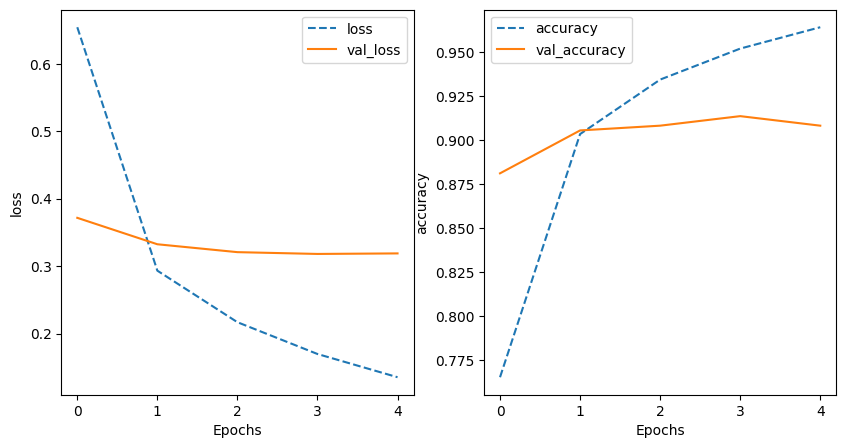

In [ ]:
model = train_and_evaluate()

1/1 [==============================] - 0s 39ms/step


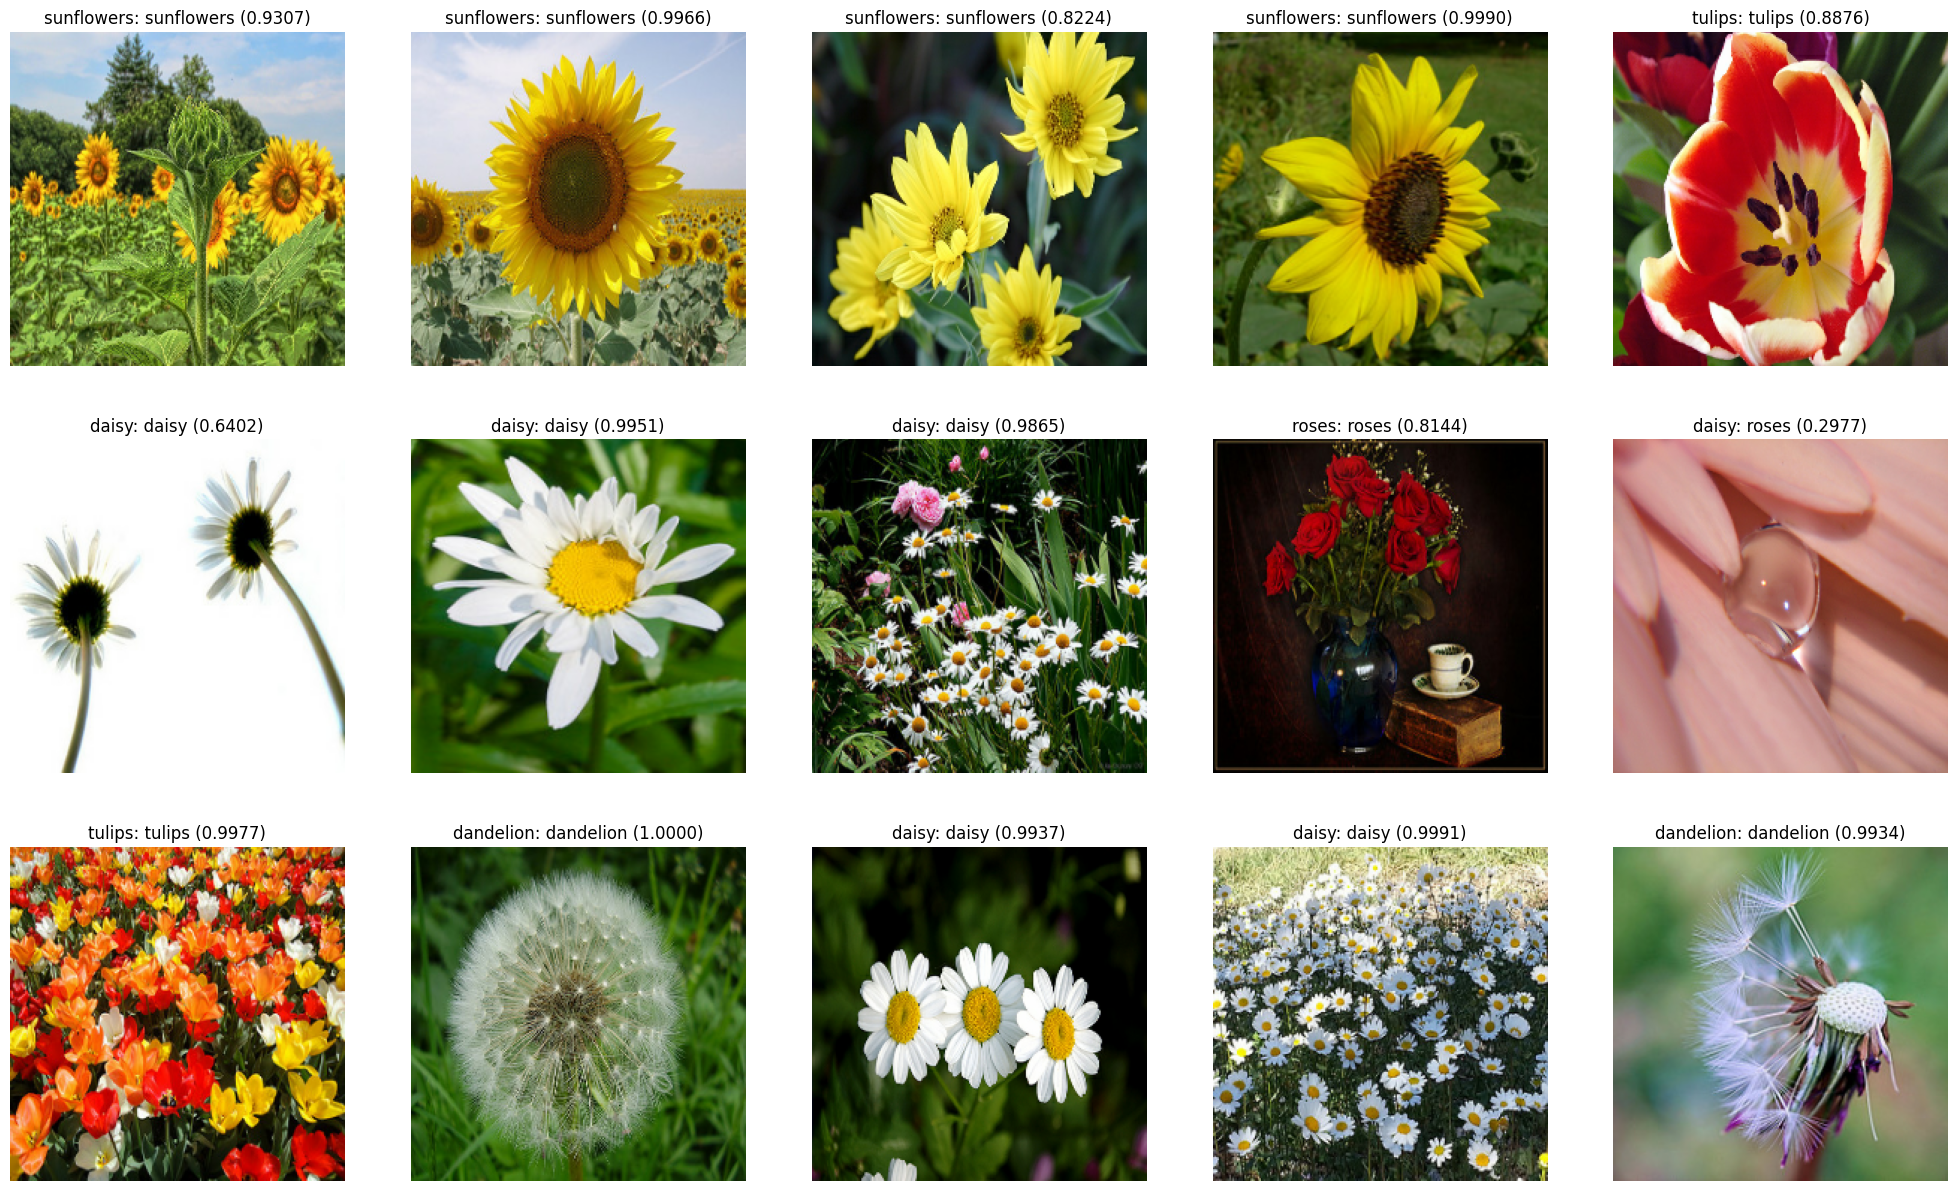

In [ ]:
plot_predictions(model, "gs://practical-ml-vision-book/flowers_5_jpeg/flower_photos/eval_set.csv")